In [1]:
# This notebook is for actual Network Training
!pip install python-chess pandas tqdm

import chess
import pandas as pd
import numpy as np

import torch
from torch import nn
from torch.utils.data import DataLoader,Dataset

np.random.seed(42)
torch.manual_seed(42)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
train_df = pd.read_csv("splits/own_train.csv")
val_df = pd.read_csv("splits/own_val.csv")
test_df = pd.read_csv("splits/own_test.csv")

print(len(train_df), len(val_df), len(test_df))
train_df.head()

77417 9677 9677


,fen,evaluation
0,3R3b/1k5p/p5n1/5pp1/8/4PP2/Pr1BN1PP/5RK1 w - -...,594
1,4k3/pp2pp2/6pb/3p3r/3p4/nP3PBP/6BR/3R2K1 w - -...,251
2,r2qkbnr/pbpp1pp1/1pn1p2p/8/1P1PP3/P1PQ4/5PPP/R...,44
3,r1b1kbr1/pp1npp2/n1p5/2P1p1pp/PP2P3/2B1Q3/3P1P...,366
4,rnb1kbnr/pp1p1ppp/4p3/8/7q/2P1pP2/PP2BNPP/RN1Q...,-789


In [3]:
# 12 * 8 * 8 channel - One channel for each chess piece

piece_to_channel = {
    'P':0,
    'N':1,
    'B':2,
    'R':3,
    'Q':4,
    'K':5,
    'p':6,
    'n':7,
    'b':8,
    'r':9,
    'q':10,
    'k':11
}

In [4]:
# Create a tensor representation of board from input : Channel for each piece type, 13th channel for whose turn
# 14th - 17th channel for castling rights  19th channel for enpassant rights
def fen_to_tensor(fen):
    board = chess.Board(fen)
    tensor = np.zeros((18,8,8), dtype=np.float32)
    # Piece channels
    for pos, piece in board.piece_map().items():
        row = 7 - chess.square_rank(pos)
        col = chess.square_file(pos)
        channel = piece_to_channel[piece.symbol()]
        tensor[channel,row,col] = 1

    # Side to move
    if board.turn == chess.WHITE:
        tensor[12,:,:] = 1

    # Castling rights
    if board.has_kingside_castling_rights(chess.WHITE):
        tensor[13,:,:] = 1
    if board.has_queenside_castling_rights(chess.WHITE):
        tensor[14,:,:] = 1
    if board.has_kingside_castling_rights(chess.BLACK):
        tensor[15,:,:] = 1
    if board.has_queenside_castling_rights(chess.BLACK):
        tensor[16,:,:] = 1

    # En passant
    if board.ep_square is not None:
        ep_row = 7 - chess.square_rank(board.ep_square)
        ep_col = chess.square_file(board.ep_square)
        tensor[17,ep_row,ep_col] = 1.

    return tensor

In [5]:
class ChessDataset(Dataset):
    def __init__(self,df):
        self.fens = df["fen"].values
        self.evals = df["evaluation"].values

    def __len__(self):
        return len(self.fens)
    
    def __getitem__(self,idx):
        x = fen_to_tensor(self.fens[idx])
        y = np.clip(self.evals[idx], -1000, 1000) / 1000.0  # Normalised input | better initialisation
        
        return (
            torch.tensor(x),
            torch.tensor([y],dtype=torch.float32)
        )
# Best Move we will not use for now - maybe in some later version

In [6]:
dataset = ChessDataset(train_df)
loader = DataLoader(dataset,batch_size=64,shuffle=True)

In [7]:
x,y = next(iter(loader))

print(x.shape)
print(y.shape)

print(x.dtype)
print(y.dtype)

torch.Size([64, 18, 8, 8])
torch.Size([64, 1])
torch.float32
torch.float32


In [8]:
train_loader = DataLoader(
    ChessDataset(train_df),
    batch_size = 64,
    shuffle = True
)

val_loader = DataLoader(
    ChessDataset(val_df),
    batch_size = 64,
    shuffle = False
)

test_loader = DataLoader(
    ChessDataset(test_df),
    batch_size = 64,
    shuffle = False
)

In [9]:
device = "mps" if torch.backends.mps.is_available() else "cpu"

In [10]:
class ResidualBlock(nn.Module):
    def __init__(self,channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(channels,channels,3,padding=1),
            nn.BatchNorm2d(channels),
            nn.ReLU(),

            nn.Conv2d(channels,channels,3,padding=1),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU()

    def forward(self,x):
        identity = x
        out = self.block(x)
        out += identity
        out = self.relu(out)
        return out

In [11]:
class ChessCNN(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(18,64,3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Dropout2d(0.1),
            ResidualBlock(64),
            ResidualBlock(64),
            ResidualBlock(64),
        )
                
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*8*8,256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256,1)
        )
    
    def forward(self,x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [12]:
model = ChessCNN().to(device)

loss_fn = nn.MSELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,mode="min",factor=0.5,patience=3,min_lr=1e-6
)

In [13]:
def train_model(model,optimizer,scheduler,train_loader,val_loader,epochs,save_path):
    best_loss = float("inf")

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        # Train
        model.train()
        running_loss = 0
        
        for X,y in train_loader:
            X = X.to(device)
            y = y.to(device)
            
            optimizer.zero_grad()
            pred = model(X)
            loss = loss_fn(pred,y)
            loss.backward()
            optimizer.step()
            
            running_loss+=loss.item()
        train_loss = running_loss/len(train_loader)
        
        # Validation
        model.eval()
        eval_loss = 0
        
        with torch.no_grad():
            for X,y in val_loader:
                X = X.to(device)
                y = y.to(device)
                
                pred = model(X)
                loss = loss_fn(pred,y)
                eval_loss += loss.item()
                
        val_loss = eval_loss/len(val_loader)
        scheduler.step(val_loss)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        print(
            f"Epoch {epoch+1}\n"
            f"Training Loss : {train_loss:.4f}\n"
            f"Validation Loss : {val_loss:.4f}\n"
            f"Learning Rate :  {optimizer.param_groups[0]['lr']:.2e}"
        )
        print("-"*40)
        
        if val_loss<best_loss:
            best_loss = val_loss
            
            torch.save(
                model.state_dict(),
                save_path
            )
    return train_losses,val_losses

train_losses,val_losses = train_model(model,optimizer,scheduler,train_loader,val_loader,50,"best_model_ChessCNN.pth")

Epoch 1
Training Loss : 0.3620
Validation Loss : 0.1172
Learning Rate :  1.00e-03
----------------------------------------
Epoch 2
Training Loss : 0.1387
Validation Loss : 0.0859
Learning Rate :  1.00e-03
----------------------------------------
Epoch 3
Training Loss : 0.1159
Validation Loss : 0.1039
Learning Rate :  1.00e-03
----------------------------------------
Epoch 4
Training Loss : 0.1055
Validation Loss : 0.0883
Learning Rate :  1.00e-03
----------------------------------------
Epoch 5
Training Loss : 0.0990
Validation Loss : 0.0589
Learning Rate :  1.00e-03
----------------------------------------
Epoch 6
Training Loss : 0.0954
Validation Loss : 0.0617
Learning Rate :  1.00e-03
----------------------------------------
Epoch 7
Training Loss : 0.0919
Validation Loss : 0.0598
Learning Rate :  1.00e-03
----------------------------------------
Epoch 8
Training Loss : 0.0892
Validation Loss : 0.0577
Learning Rate :  1.00e-03
----------------------------------------
Epoch 9
Training

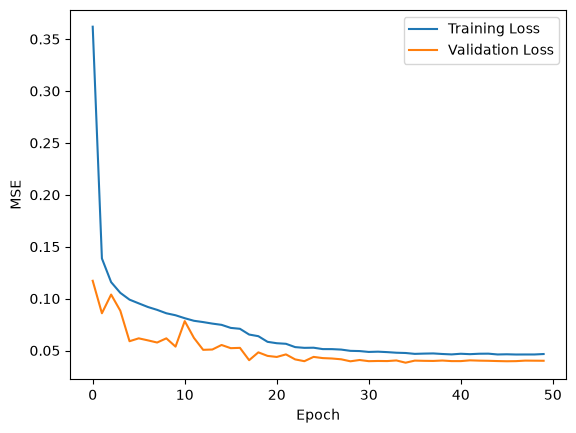

In [14]:
import matplotlib.pyplot as plt
plt.plot(train_losses,label="Training Loss")
plt.plot(val_losses,label = "Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [15]:
def evaluate(loader,*models):
    for m in models:
        m.eval()

    abs_err = 0
    sq_err = 0
    n = 0
    correct = 0
    n_decisive = 0

    with torch.no_grad():
        for X,y in loader:
            X = X.to(device)
            y = y.to(device)

            pred = sum(m(X) for m in models)/len(models)

            abs_err += torch.abs(pred-y).sum().item()
            sq_err += ((pred-y)**2).sum().item()
            n += y.size(0)

            decisive = torch.abs(y) > 0.05
            correct += (torch.sign(pred[decisive]) == torch.sign(y[decisive])).sum().item()
            n_decisive += decisive.sum().item()

    mae = abs_err/n*1000
    rmse = (sq_err/n)**0.5*1000
    sign_acc = correct/n_decisive

    print(f"Centipawn MAE  : {mae:.2f}")
    print(f"Centipawn RMSE : {rmse:.2f}")
    print(f"Sign accuracy (|eval| > 50cp) : {sign_acc:.4f}")
    return mae,rmse,sign_acc


def baseline(train_df,test_df):
    y_train = np.clip(train_df["evaluation"].values, -1000, 1000)
    y_test = np.clip(test_df["evaluation"].values, -1000, 1000)
    pred = np.mean(y_train)

    print(f"Centipawn MAE  : {np.mean(np.abs(y_test-pred)):.2f}")
    print(f"Centipawn RMSE : {np.sqrt(np.mean((y_test-pred)**2)):.2f}")


model.load_state_dict(torch.load("best_model_ChessCNN.pth"))

print("Baseline (predict mean) on own test set")
baseline(train_df,test_df)
print()
print("Model on own test set")
evaluate(test_loader,model)

Baseline (predict mean) on own test set
Centipawn MAE  : 480.12
Centipawn RMSE : 580.43

Model on own test set
Centipawn MAE  : 133.17
Centipawn RMSE : 194.05
Sign accuracy (|eval| > 50cp) : 0.9245


(133.17195233621663, 194.04763820823894, 0.9244809491216062)

In [16]:
k_train_df = pd.read_csv("splits/kaggle_train.csv")
k_val_df = pd.read_csv("splits/kaggle_val.csv")
k_test_df = pd.read_csv("splits/kaggle_test.csv")

print(k_train_df.head())
print(len(k_train_df), len(k_val_df), len(k_test_df))

                                                 fen  evaluation
0            8/8/5np1/7p/5Pk1/1R4P1/5K2/8 w - - 0 54         105
1  r1bqk1nr/pppp1ppp/2n5/4p3/2PP4/2P2N2/P3PPPP/R1...          51
2  rnbq1rk1/ppppnpbp/4p1p1/8/2PP4/P1N1P2P/1P3PP1/...          19
3  5rk1/ppqrb1pp/4bn2/8/1n6/1PN1B1P1/P3QPBP/3R1RK...         -99
4  5rk1/2q2pp1/3p1n1p/4p3/Q1P1N2R/P7/2P1KP2/8 b -...        -326
6140297 767537 767537


In [17]:
print(k_train_df["evaluation"].describe())

count    6.140297e+06
mean     1.602096e+01
std      6.010743e+02
min     -7.847000e+03
25%     -1.880000e+02
50%      1.200000e+01
75%      2.250000e+02
max      8.482000e+03
Name: evaluation, dtype: float64


In [18]:
k_train_loader = DataLoader(ChessDataset(k_train_df),batch_size=64,shuffle=True)
k_val_loader = DataLoader(ChessDataset(k_val_df),batch_size=64,shuffle=False)
k_test_loader = DataLoader(ChessDataset(k_test_df),batch_size=64,shuffle=False)

model = ChessCNN().to(device)
model.load_state_dict(torch.load("best_model_ChessCNN.pth"))

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr = 1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [19]:
# Transfer Learning the model trained on handmade data (Depth=12) onto Kaggle data

ft_train_losses,ft_val_losses = train_model(model,optimizer,scheduler,k_train_loader,k_val_loader,10,"ChessCNN_kaggle_finetuned.pth")

Epoch 1
Training Loss : 0.0461
Validation Loss : 0.0320
Learning Rate :  1.00e-04
----------------------------------------
Epoch 2
Training Loss : 0.0426
Validation Loss : 0.0289
Learning Rate :  1.00e-04
----------------------------------------
Epoch 3
Training Loss : 0.0412
Validation Loss : 0.0281
Learning Rate :  1.00e-04
----------------------------------------
Epoch 4
Training Loss : 0.0402
Validation Loss : 0.0282
Learning Rate :  1.00e-04
----------------------------------------
Epoch 5
Training Loss : 0.0395
Validation Loss : 0.0274
Learning Rate :  1.00e-04
----------------------------------------
Epoch 6
Training Loss : 0.0388
Validation Loss : 0.0265
Learning Rate :  1.00e-04
----------------------------------------
Epoch 7
Training Loss : 0.0383
Validation Loss : 0.0249
Learning Rate :  1.00e-04
----------------------------------------
Epoch 8
Training Loss : 0.0378
Validation Loss : 0.0274
Learning Rate :  1.00e-04
----------------------------------------
Epoch 9
Training

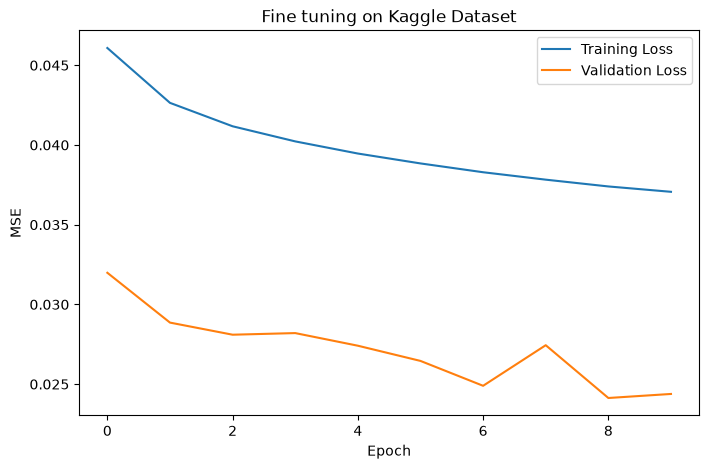

In [20]:
plt.figure(figsize=(8,5))

plt.plot(ft_train_losses,label="Training Loss")
plt.plot(ft_val_losses,label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Fine tuning on Kaggle Dataset")
plt.legend()

plt.show()

In [21]:
# Same model trained only on Kaggle data without pretraining

scratch_model = ChessCNN().to(device)

optimizer = torch.optim.AdamW(
    scratch_model.parameters(),
    lr = 1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,mode="min",factor=0.5,patience=3,min_lr=1e-6
)

sc_train_losses,sc_val_losses = train_model(scratch_model,optimizer,scheduler,k_train_loader,k_val_loader,10,"ChessCNN_kaggle_scratch.pth")

KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(sc_train_losses,label="Training Loss")
plt.plot(sc_val_losses,label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training from scratch on Kaggle Dataset")
plt.legend()

plt.show()

In [22]:
pretrained = ChessCNN().to(device)
pretrained.load_state_dict(torch.load("best_model_ChessCNN.pth"))

finetuned = ChessCNN().to(device)
finetuned.load_state_dict(torch.load("ChessCNN_kaggle_finetuned.pth"))

# scratch = ChessCNN().to(device)
# scratch.load_state_dict(torch.load("ChessCNN_kaggle_scratch.pth"))

print("Baseline (predict mean)")
baseline(k_train_df,k_test_df)
print()
print("Pretrained on own data only")
evaluate(k_test_loader,pretrained)
print()
# print("Trained from scratch on Kaggle")
# evaluate(k_test_loader,scratch)
print()
print("Pretrained + fine tuned on Kaggle")
evaluate(k_test_loader,finetuned)
print()
print("Ensemble (pretrained + fine tuned)")
evaluate(k_test_loader,pretrained,finetuned)

Baseline (predict mean)
Centipawn MAE  : 295.08
Centipawn RMSE : 401.64

Pretrained on own data only
Centipawn MAE  : 165.23
Centipawn RMSE : 226.30
Sign accuracy (|eval| > 50cp) : 0.8451


Pretrained + fine tuned on Kaggle
Centipawn MAE  : 106.11
Centipawn RMSE : 154.97
Sign accuracy (|eval| > 50cp) : 0.9278

Ensemble (pretrained + fine tuned)
Centipawn MAE  : 123.88
Centipawn RMSE : 174.51
Sign accuracy (|eval| > 50cp) : 0.8949


(123.87542265550707, 174.50905127569328, 0.8948979507004199)